In [1]:
## This script prepares text files containing the details of each run for presenting stimuli using PsycoPy
# Run with python 3.10 fMRI env
# James Fodor 2023

# load libraries
import numpy as np
import sys
import random
import pandas as pd
import matplotlib.pyplot as plt
import os

# load custom functions from library
sys.path.insert(0,'./..')
import voxels_processing as vp

# numpy print options
np.set_printoptions(precision=4, threshold=500, linewidth=220, suppress=True, floatmode='fixed')
pd.set_option('display.max_rows', 400)

## Load sentences and questions

In [5]:
## Load sentence set 

# select sentence dataset and specify if sentence pairs
dataset_name = 'Fodor2024-final108'
sims_path = 'Data-models/similarities/'

# load sentence set into dictionary depending on type
sentences_dict = vp.load_set_of_sentences('../'+dataset_name+'_sentences', pairs=False)
n = len(sentences_dict.keys()) # num sentences
print('Loaded',dataset_name,'with',n,'sentences')

# store in list
all_sentences = list(sentences_dict.values())

Loaded Fodor2024-final108 with 108 sentences


In [7]:
## Load and store set of questions
questions = np.loadtxt('../Fodor2024-final108_questions.txt',  delimiter=';', dtype='str', encoding='utf-8', skiprows=1)
questions_dict = {}
for question in questions:
    sentence_id = question[0]
    questions_dict[int(sentence_id)] = list(question[1:-1])
print('Loaded',len(questions_dict.keys()),'questions')

Loaded 108 questions


## Prepare sentence presentation files

In [8]:
## Set subject ID
subject_id = '50'

## Save dictionary of stimulus duration times
durations_dict = {}
for sentence_id in sentences_dict.keys():
    sentence_len = len(sentences_dict[sentence_id]) # in chars
    time_per_char = 0.055 # in s (old value was 0.06)
    squared_coef = 0.012 # coefficient on quadratic term adding extra time for long sentences (old value was 0.02)
    durations_dict[sentence_id] = ((sentence_len*time_per_char) + squared_coef*(sentence_len*time_per_char)**2)*1000 # in ms
    
num_sentences = len(sentences_dict.keys())
print(len(sentences_dict.keys()),'sentences with mean duration',np.mean(list(durations_dict.values())),'milliseconds')
num_repeats = 4


## Generate set of inter-stimulus intervals for a single run
inter_stim_times = np.linspace(start=2000,stop=7000,num=int(n/(8/num_repeats)))
sents_per_run = len(inter_stim_times)
print(sents_per_run,'intervals')


## Split longer sentences across two lines for display to participants
sentences_print_dict = {}
for sent_id in list(sentences_dict.keys()):
    sent = sentences_dict[sent_id]
    sent_words = sent.split() # words in a list
    sent_length = len(sent_words)
    
    halfway = int(sent_length/2)
    long_cutoff = 10 # cutoff for what counts as 'long'
    if sent_length > long_cutoff: 
        sent_top_line = ' '.join(sent_words[0:halfway]) 
        sent_bottom_line = ' '.join(sent_words[halfway:])
        sentences_print_dict[sent_id] = sent_top_line+'\\n'+sent_bottom_line
    else:
        sentences_print_dict[sent_id] = sent


## Assign all sentences to one of eight runs, each with the same number of questions and a similar total length
questions_balanced = False # keeps track of whether the runs are balanced
while questions_balanced==False: # loop until each run has equal number of questions
    
    # Generate list of runs in random order
    runs = []
    for indx in np.arange(0,sents_per_run): 
        runset = np.arange(1,int(8/num_repeats)+1)
        random.shuffle(runset)
        runs.append(runset)
    
    # Extend list of runs across all repeats
    runs_1 = np.array(runs).flatten()
    runs_all = np.array([],dtype=int)
    for rep in np.arange(num_repeats):
        runs_2 = runs_1 + int(rep*(8/num_repeats))
        runs_all = np.append(runs_all, runs_2)

    # Storage of sentence indexes by run
    sentence_ids_by_duration = list(dict(sorted(durations_dict.items(), key=lambda item: item[1])).keys())
    all_ordered_sentence_ids = sentence_ids_by_duration * num_repeats # multiple copies of sentences_by_duration for the repeats
    runs_sents_tuples = list(tuple(zip(all_ordered_sentence_ids, runs_all))) # create list of tuples of sentence_id and run_id pairs

    # Create new dictionary organising sentences by run
    runset = np.arange(1,9)
    sentences_by_run = dict(zip(runset, [{} for _ in runset])) # blank dictionary
    for run_sent_tuple in runs_sents_tuples:
        sentence_id = run_sent_tuple[0]
        run_id = run_sent_tuple[1]
        sentences_by_run[run_id][sentence_id] = sentences_dict[sentence_id]
        
    # Check number of questions by run
    question_count = []
    for run in sentences_by_run.keys():
        cumulative_count = 0
        for sentence_id in sentences_by_run[run]:
            cumulative_count+=int(questions_dict[sentence_id][0])/4
        question_count.append(int(cumulative_count))

    # Check if questions are balanced over runs
    if len(set(question_count))==1:
        questions_balanced = True
print('question count:',question_count)

# Stimulus duration length check for each run
total_duration = 508 # target total duration in seconds
end_fixation_times = []
for run in np.arange(1,9):
    total_length = 0
    for sentence_id in sentences_by_run[run]:
        total_length += durations_dict[sentence_id]
    total_sent_duration = (total_length+np.sum(inter_stim_times))/(1000)
    num_sents = len(sentences_by_run[run].keys())
    total_question_length = 5*(40/8) # five seconds per question
    end_fixation_times.append(total_duration-total_question_length-total_sent_duration)
    print('run',run,'with',num_sents,'sents lasting a total of',str(total_sent_duration+total_question_length)[0:5],'seconds')
    # print('run end fixation:',total_duration-total_sent_duration)
print('End fixation times',end_fixation_times)

## Print list of sentence IDs with questions by the run in which they appear
questions_by_run = {1:[], 2:[], 3:[], 4:[], 5:[], 6:[], 7:[], 8:[]}
all_questions_used = []
for iteration in np.arange(0,5):
    for run in np.arange(1,9):
        for sent_id in sentences_by_run[run]:
            if questions_dict[sent_id][0] == '0': # skip sentences without questions
                continue
            elif sent_id in all_questions_used: # go to next sent_id if this one has already been assigned
                continue
            else:
                questions_by_run[run].append(sent_id) # assign a question to a run
                all_questions_used.append(sent_id)
                break # go to next run
print(questions_by_run)


## Organise questions into first and second sets of four runs for balancing
runset = np.arange(1,9)
included_questions = dict(zip(runset, [[] for _ in runset])) # make empty dictionary

# work out set of questions in runs 1-4
for i in np.arange(8):
    for run in [1,2,3,4]:
        for sentence_id in sentences_by_run[run].keys():
            if questions_dict[sentence_id][0]!='0' and sentence_id not in included_questions[run]: # only get sent_ids with questions and if not yet added to list
                included_questions[run].append(sentence_id)
                break
first_half_questions = np.array(list(included_questions.values())[0:4]).flatten() # questions in runs 1-4

# now work out set of questions in runs 5-8
for run in [5,6,7,8]:
    for sentence_id in sentences_by_run[run].keys():
        if questions_dict[sentence_id][0]!='0' and sentence_id not in first_half_questions: # only get sent_ids with questions and not in first half of runs
            included_questions[run].append(sentence_id)
    

108 sentences with mean duration 4286.579814814815 milliseconds
54 intervals
question count: [20, 20, 20, 20, 20, 20, 20, 20]
run 1 with 54 sents lasting a total of 499.6 seconds
run 2 with 54 sents lasting a total of 499.2 seconds
run 3 with 54 sents lasting a total of 499.6 seconds
run 4 with 54 sents lasting a total of 499.2 seconds
run 5 with 54 sents lasting a total of 499.6 seconds
run 6 with 54 sents lasting a total of 499.2 seconds
run 7 with 54 sents lasting a total of 499.6 seconds
run 8 with 54 sents lasting a total of 499.2 seconds
End fixation times [np.float64(8.33653060000006), np.float64(8.712849399999982), np.float64(8.33653060000006), np.float64(8.712849399999982), np.float64(8.33653060000006), np.float64(8.712849399999982), np.float64(8.33653060000006), np.float64(8.712849399999982)]
{1: [12, 77, 37, 51, 89], 2: [3, 58, 46, 17, 108], 3: [94, 22, 20, 70, 18], 4: [93, 66, 105, 98, 26], 5: [4, 73, 50, 8, 53], 6: [11, 28, 61, 16, 72], 7: [10, 30, 96, 25, 80], 8: [32, 85,

In [ ]:
## Generate all runs with randomised question order
all_runs_all_sentence_info = {}
for run in np.arange(1,9):
    
    # Get sentences for this run
    sent_ids_in_run = list(sentences_by_run[run].keys()).copy()
    
    # Save set of question multi-choice options
    correct_answers = ['A','B','C','D']*2 # eight questions per run
    
    # Shuffle the sentence order within the run
    random.shuffle(sent_ids_in_run)
    
    # Shuffle the order of inter-stimulus intervals
    random.shuffle(inter_stim_times)
    
    # Loop over each sentence in the run
    all_sentence_info = []
    i=0 # index over sentences in a run
    j=0 # index over answers
    for sentence_id in sent_ids_in_run:
        
        # Get basic details for the sentence
        sentence_text = sentences_print_dict[sentence_id]
        sentence_duration = durations_dict[sentence_id]/1000
        interstim_time = inter_stim_times[i]/1000
        question_info = questions_dict[sentence_id]
        question_duration = 5 if (sentence_id in questions_by_run[run]) else 0 # split questions by first and second set of runs
        question = question_info[1]
        
        # Compute appropriate ordering of options for each question
        if question_duration>0: # only for sentences with questions
            # print(run,i,j,question)
            correct_answer = question_info[3]
            correct_answer_position = j%4 # store correct answer position
            all_answers = question_info[4:7] # get the incorrect answers
            random.shuffle(all_answers) # shuffle the order
            all_answers.insert(correct_answer_position,correct_answer) # insert the correct answer in the desired position
            correct_answer_index_display = correct_answers[j]
            j+=1 # keep track of position in the correct answer indices
        else:
            correct_answer_index_display = 'None'
            all_answers = question_info[2:6] # for sentences without a question
        
        # Add letter options for questions
        all_answers_final = []
        question_letters = ['A) ','B) ','C) ','D) ']
        for idx in np.arange(0,4):
            all_answers_final.append(question_letters[idx]+all_answers[idx])

        # Store all details for each sentence
        all_info_for_sentence = [sentence_id,sentence_text,sentence_duration,interstim_time,question_duration,question,correct_answer_index_display]+all_answers_final
        all_sentence_info.append(all_info_for_sentence)
        i+=1
        
    # Store all details for all sentences in a run and save
    random.shuffle(all_sentence_info)
    all_runs_all_sentence_info[run] = all_sentence_info
    header_row = 'sentence_id;sentence_text;sentence_duration;interstim_duration;question_duration;question_text;answer_index;option_1;option_2;option_3;option_4'
    folder_name = '../subject_'+subject_id
    if not os.path.exists(folder_name):
        os.makedirs(folder_name)
    np.savetxt(folder_name+"/run_"+str(run)+".csv", all_runs_all_sentence_info[run], fmt='%s', delimiter=';', header=header_row, comments='')


## Generate 'runs' file which lists all the individual run files for Psychopy to load in succession
runs_output_file = []
header_row = 'run_file;intro_text;final_fixation_time'
for i in np.arange(1,9):
    path_root = '../subject_'+subject_id+'/run_' # location of where the run files will be
    file_path = path_root+str(i)+'.csv'
    if i==0:
        welcome_text = 'The practise run will begin shortly.'
    else:
        welcome_text = 'Run '+str(i)+' of 8 will begin shortly.'
    final_fixation_length = end_fixation_times[i-1]
    runs_output_file.append([file_path,welcome_text,final_fixation_length])
np.savetxt(folder_name+"/runs.csv", runs_output_file, fmt='%s', delimiter=';', header=header_row, comments='')

## Quality control checking

In [86]:
# Print out all stimuli in table for checking
headers = ['sentence_id','sentence_text','sentence_duration','interstim_duration','question_duration','question_text','answer_index','option_1','option_2','option_3','option_4']
df = pd.DataFrame()
for run in all_runs_all_sentence_info.keys():
    all_sent_data = all_runs_all_sentence_info[run]
    for sent in all_sent_data:
        new_part = pd.DataFrame(all_sent_data, columns=headers)
        
    new_part = pd.DataFrame(all_sent_data, columns=headers)
    df = pd.concat([df, new_part])
df.head(54)

,sentence_id,sentence_text,sentence_duration,interstim_duration,question_duration,question_text,answer_index,option_1,option_2,option_3,option_4
0,92,The shopkeeper displayed the watch for his cus...,3.016967,3.320755,0,None,None,A) None,B) None,C) None,D) None
1,70,The group of children objected to the unpleasa...,5.367243,4.547170,0,Where was the dog from?,None,A) The park,B) The park,C) The beach,D) The store
2,108,In the back room the nosey customer watched ov...,6.489230,5.584906,0,Where did the customer watch the monitor?,None,A) In the back room,B) In the back room,C) Behind the counter,D) Near the entrance
3,37,The company purchased the apartment block from...,3.312113,6.905660,0,Who purchased the apartment block?,None,A) The compnay,B) The investor,C) The family,D) The company
4,69,The children rarely objected to the\nunpleasan...,4.510849,4.735849,0,None,None,A) None,B) None,C) None,D) None
5,99,As a marketing technique the shopkeeper promin...,6.112621,4.452830,0,None,None,A) None,B) None,C) None,D) None
6,100,The customer watched over the display for the ...,3.252939,3.509434,0,None,None,A) None,B) None,C) None,D) None
7,104,The customer watched over the model for the sh...,3.134807,2.283019,0,None,None,A) None,B) None,C) None,D) None
8,58,The dog noticed the strange object near the ch...,3.016967,3.603774,0,Who saw the strange object?,None,A) The dog,B) The dog,C) The children,D) The mother
9,78,In response to recent events the lobbyist\nqui...,5.428959,6.339623,0,None,None,A) None,B) None,C) None,D) None


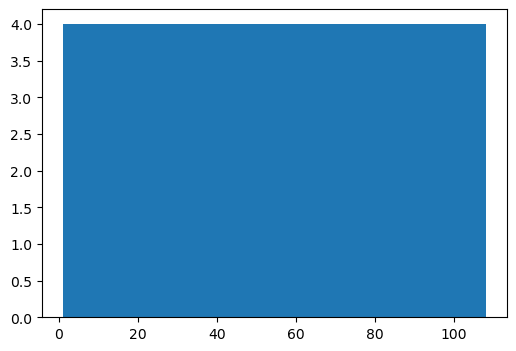

In [87]:
# Check that each sentence ID appears twice exactly
fig = plt.figure(figsize=(6,4))
plt.hist(df['sentence_id'].values, bins=n)
plt.show()

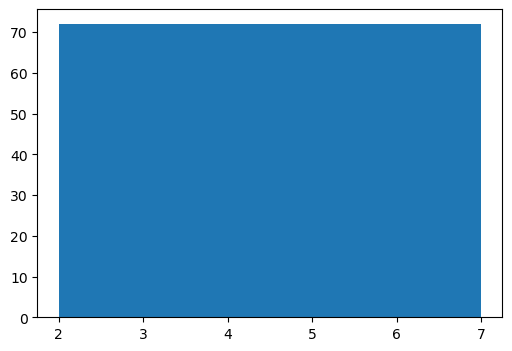

In [83]:
# Check distribution of interstimulus durations
fig = plt.figure(figsize=(6,4))
plt.hist(df['interstim_duration'].values, bins=6)
plt.show()

In [ ]:
# Check Length of each run in s
for run_id in np.arange(1,9):
    start_index = (run_id-1)*54
    end_index = start_index+54
    total_sentence_duration = np.sum(df['sentence_duration'].values[start_index:end_index])
    total_interstim_duration = np.sum(df['interstim_duration'].values[start_index:end_index])
    total_question_duration = np.sum(df['question_duration'].values[start_index:end_index])
    print('Run:',run_id)
    print('  sentences:',total_sentence_duration)
    print('  interstim:',total_interstim_duration)
    print('  questions:',total_question_duration)
    print('  fixations:',end_fixation_times[run_id-1])
    print('  totaltime:',total_sentence_duration+total_interstim_duration+total_question_duration+end_fixation_times[run_id-1])

Run: 1
  sentences: 231.40027239999998
  interstim: 243.0
  questions: 25
  fixations: 8.599727599999994
  totaltime: 507.99999999999994
Run: 2
  sentences: 231.4873253
  interstim: 243.0
  questions: 25
  fixations: 8.512674699999991
  totaltime: 508.0
Run: 3
  sentences: 231.40027239999998
  interstim: 243.0
  questions: 25
  fixations: 8.599727599999994
  totaltime: 507.99999999999994
Run: 4
  sentences: 231.48732530000004
  interstim: 243.0
  questions: 25
  fixations: 8.512674699999991
  totaltime: 508.00000000000006
Run: 5
  sentences: 231.40027239999995
  interstim: 242.99999999999997
  questions: 25
  fixations: 8.599727599999994
  totaltime: 507.99999999999994
Run: 6
  sentences: 231.48732530000004
  interstim: 243.0
  questions: 25
  fixations: 8.512674699999991
  totaltime: 508.00000000000006
Run: 7
  sentences: 231.40027239999998
  interstim: 243.0
  questions: 25
  fixations: 8.599727599999994
  totaltime: 507.99999999999994
Run: 8
  sentences: 231.48732530000004
  interst